# CSCI 3003 — Data Visualization
## Lab 7: Multivariate Visualization and Multiple Regression

**Name:**  Steve Tatsiguia
**Date:**  10/22/2026

### Learning objectives

- Choose grouped encodings or facets for a multivariate question.
- Reshape selected measurements and interpret a focused correlation heatmap.
- Fit a numeric-response model with several predictors and diagnose it visually.
- Interpret conditional coefficients without claiming causation or unseen-data performance.

### Online workflow

Work through each short explanation and example in order. Pause to predict the
output before running unfamiliar code. Complete each question before opening a
later **Check your work** section. These checks support selected complex tasks;
they do not supply answers to the independent investigation. Add code/Markdown
cells when needed. Submit the completed HTML export only.

## I. Setup and dataset

We continue with Palmer Penguins so the new difficulty is multivariate reasoning.
One row is a penguin measurement. `body_mass_g` is mass in grams;
`flipper_length_mm`, `bill_length_mm`, and `bill_depth_mm` are millimeter
measurements. `species`, `island`, and `sex` are recorded categories; `year` is
the observation year. Missing values occur. Do not treat penguins as a random
sample of every penguin population.

Source: Horst, Hill, and Gorman (2020),
[Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), CC0;
the existing course CSV is reused without alteration.

Open the complete course folder in VS Code and choose the course Python kernel.
The configured Jupyter working directory must be `01-labs/`; opening the folder
alone does not guarantee this. Confirm the files below in Explorer, then run the
directory and existence checks. Correct any `False` result before loading data.
Packages are installed through the course setup instructions separately from
these routine imports; do not reinstall them every time you run the notebook.



In [38]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

Path.cwd()

WindowsPath('c:/Users/steve/OneDrive/Documents/CSCI-3003-Data-Visualization/01-labs')

In [39]:
print("penguins.csv:", Path("penguins.csv").exists())

penguins.csv: True


In [40]:
penguins = pd.read_csv("penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## II. One question, several encodings

We ask how body mass relates to flipper length and whether species adds useful
context. Use `.dropna(subset=...)` only for variables needed in this analysis,
and `.copy()` when creating a separate editable table. Numeric-coded categories
are not automatically quantitative measurements.



In [41]:
relationship_data = penguins.dropna(
    subset=["body_mass_g", "flipper_length_mm", "species"]
).copy()
print("Original rows:", len(penguins), "Analysis rows:", len(relationship_data))
relationship_data.groupby("species").agg(
    n=("body_mass_g", "size"), median_mass_g=("body_mass_g", "median")
)

Original rows: 344 Analysis rows: 342


,n,median_mass_g
species,,
Adelie,151,3700.0
Chinstrap,68,3700.0
Gentoo,123,5000.0


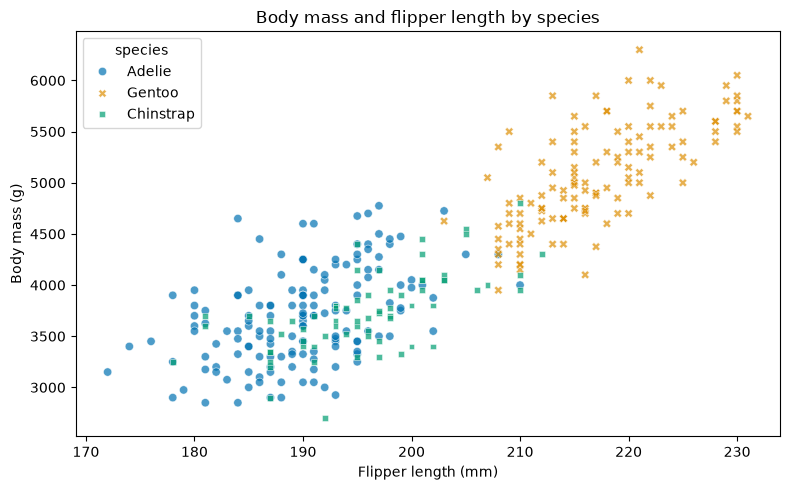

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=relationship_data,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    style="species",
    palette="colorblind",
    alpha=0.7,
    ax=ax,
)
ax.set(
    xlabel="Flipper length (mm)",
    ylabel="Body mass (g)",
    title="Body mass and flipper length by species",
)
fig.tight_layout()
plt.show()

`sns.relplot()` is a figure-level function: it creates its own figure and panels.
`col` chooses the faceting column, `col_order` controls panel order, and
`facet_kws` passes shared-axis settings. `grid.set_axis_labels()` labels all
panels. Do not pass an existing `ax` to this figure-level function.



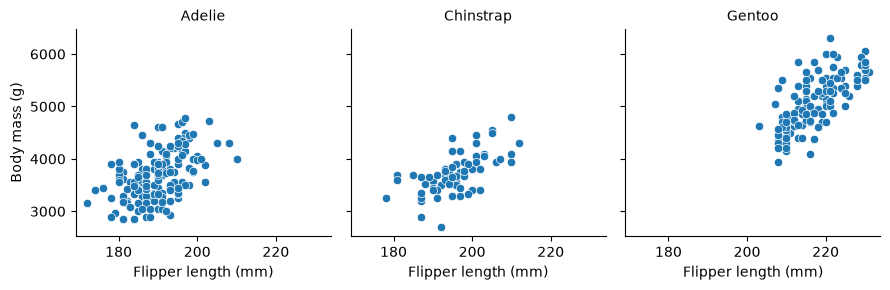

In [43]:
species_order = ["Adelie", "Chinstrap", "Gentoo"]
grid = sns.relplot(
    data=relationship_data,
    x="flipper_length_mm",
    y="body_mass_g",
    col="species",
    col_order=species_order,
    kind="scatter",
    height=3,
    aspect=1,
    facet_kws={"sharex": True, "sharey": True},
)
grid.set_axis_labels("Flipper length (mm)", "Body mass (g)")
grid.set_titles("{col_name}")
plt.show()

**Question 1**

Compare the combined chart and facets. Which better supports a within-species comparison? Which better supports a between-species comparison? Explain a cost of your preferred layout.

**Answer:** Facets make within-species patterns easier to see because the groups are separated. The combined chart makes between-species differences easier to compare on one set of axes. I prefer facets for within-species comparisons, but they take more space and require looking between panels.


**Question 2**

Make a grouped chart and faceted chart of bill length versus bill depth, using the same complete rows and comparable axes. Justify color, shape, and panel choices. Avoid also encoding body mass through marker size unless it serves a clear question.

**Answer:** Both charts use the same rows with complete bill measurements. Color and shape identify species in the grouped chart, so species can still be distinguished without color alone. The colorblind palette makes the colors easier to distinguish. One panel per species reduces overlap and makes within-species patterns clearer. The facets follow Adelie, Chinstrap, and Gentoo order and share the same axis limits as the grouped chart for fair comparisons.


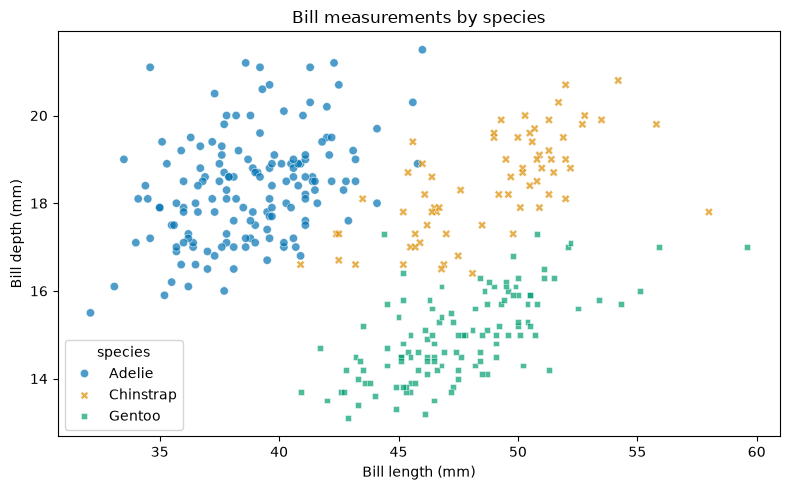

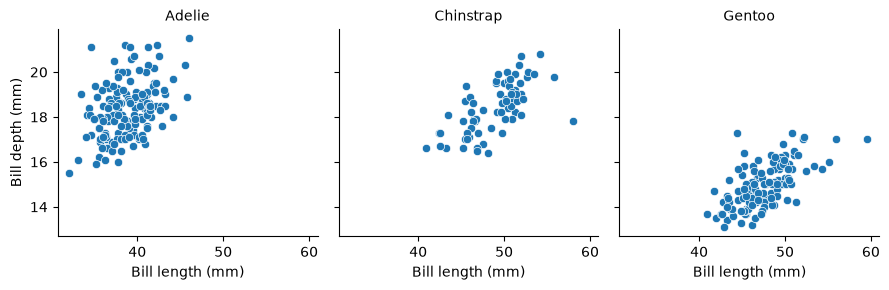

In [44]:
bill_data = penguins.dropna(
    subset=["bill_length_mm", "bill_depth_mm", "species"]
).copy()
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=bill_data, x="bill_length_mm", y="bill_depth_mm",
    hue="species", style="species", hue_order=species_order,
    style_order=species_order, palette="colorblind", alpha=0.7, ax=ax,
)
ax.set(xlabel="Bill length (mm)", ylabel="Bill depth (mm)",
       title="Bill measurements by species")
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()
fig.tight_layout()
plt.show()

grid = sns.relplot(
    data=bill_data, x="bill_length_mm", y="bill_depth_mm",
    col="species", col_order=species_order, kind="scatter",
    height=3, aspect=1, facet_kws={"sharex": True, "sharey": True},
)
grid.set(xlim=x_limits, ylim=y_limits)
grid.set_axis_labels("Bill length (mm)", "Bill depth (mm)")
grid.set_titles("{col_name}")
plt.show()

## III. Reshaping and selected relationships

`.melt()` turns selected wide measurement columns into a measurement-name column
and value column. `id_vars` stays as identifying context; `value_vars` lists the
measurements to reshape. Only combine measurements with compatible units in a
shared comparison. Flipper and bill lengths are both millimeters but have very
different ranges, so their raw values answer a different question from standardized
measurements.



In [45]:
length_data = (
    penguins[["species", "bill_length_mm", "bill_depth_mm"]]
    .melt(
        id_vars="species",
        value_vars=["bill_length_mm", "bill_depth_mm"],
        var_name="measurement",
        value_name="length_mm",
    )
    .dropna(subset=["length_mm"])
)
length_data.head()

,species,measurement,length_mm
0,Adelie,bill_length_mm,39.1
1,Adelie,bill_length_mm,39.5
2,Adelie,bill_length_mm,40.3
4,Adelie,bill_length_mm,36.7
5,Adelie,bill_length_mm,39.3


**Question 3**

Use `length_data` to create one box plot per measurement with species groups. Explain why a shared y-axis could obscure one comparison. Keep category order deliberate.

**Answer:** Bill lengths are much larger than bill depths. A shared y-axis would compress the bill-depth boxes and make species differences harder to see. Separate y-scales show each distribution clearly, but heights cannot be compared directly across panels.


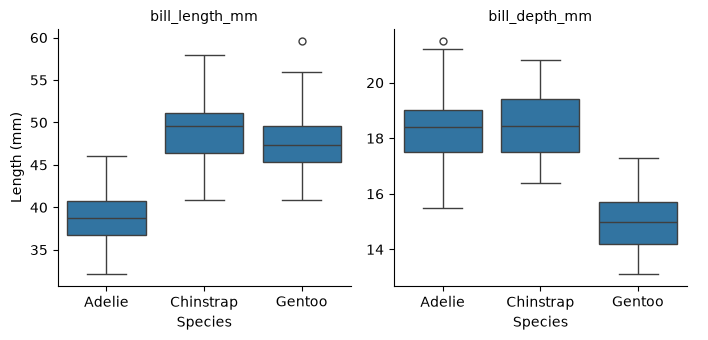

In [46]:
grid = sns.catplot(
    data=length_data, x="species", y="length_mm", col="measurement",
    order=species_order, col_order=["bill_length_mm", "bill_depth_mm"],
    kind="box", sharey=False, height=3.5, aspect=1,
)
grid.set_axis_labels("Species", "Length (mm)")
grid.set_titles("{col_name}")
plt.show()

A Pearson correlation describes linear association, not causation. `.corr()`
calculates pairwise correlations; `sns.heatmap()` maps table values to color.
Use a diverging palette centered at zero and fixed bounds −1 and 1. `annot=True`
prints values; `fmt=".2f"` displays two decimals. Here complete cases keep the
same rows in every pair. Group structure can affect a pooled correlation.



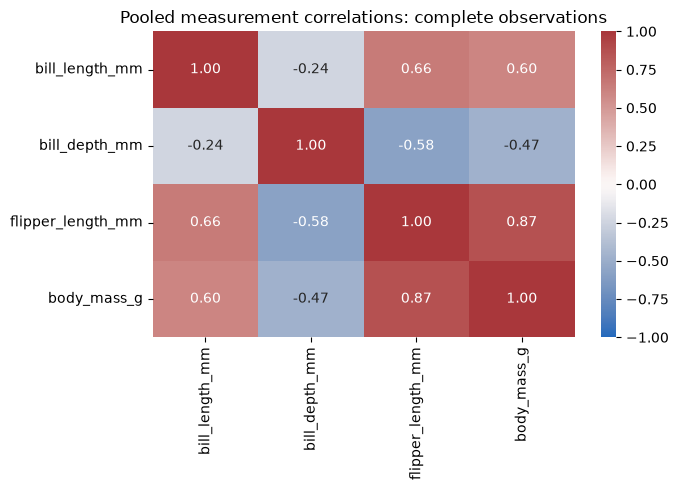

In [47]:
numeric_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
numeric_data = penguins[numeric_columns].dropna()
correlations = numeric_data.corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    correlations, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", ax=ax
)
ax.set_title("Pooled measurement correlations: complete observations")
fig.tight_layout()
plt.show()

**Question 4**

Choose one strong or surprising heatmap entry. Inspect it in a species-coded scatterplot. Explain what the scatterplot reveals that the heatmap hides.

**Answer:** Bill depth and body mass have a pooled correlation of about -0.47. However, the scatterplot shows a positive relationship within each species. Gentoo penguins are generally heavier but have shallower bills, which helps explain the negative pooled correlation. The heatmap hides these species groups.


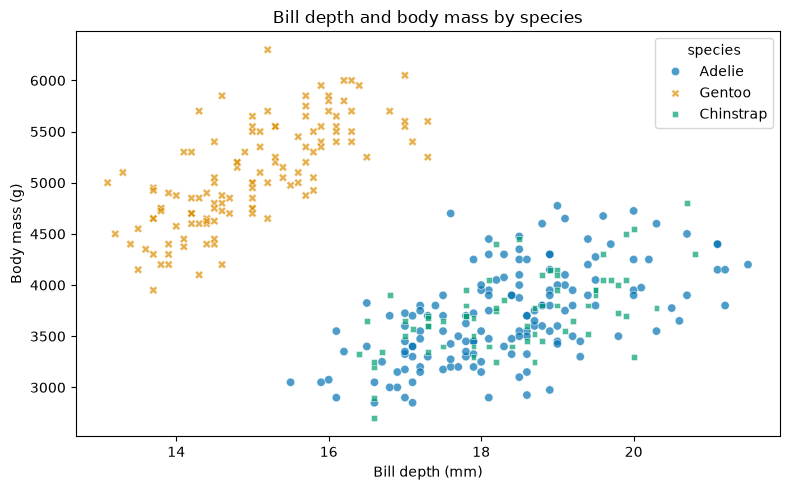

In [48]:
heatmap_data = penguins.dropna(subset=numeric_columns + ["species"]).copy()
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=heatmap_data, x="bill_depth_mm", y="body_mass_g",
    hue="species", style="species", palette="colorblind", alpha=0.7, ax=ax,
)
ax.set(xlabel="Bill depth (mm)", ylabel="Body mass (g)",
       title="Bill depth and body mass by species")
fig.tight_layout()
plt.show()

<div style="height:180px" aria-hidden="true"></div>

---

### Check your work — Question 3

Attempt the question and write your response before reading this section.

A figure-level categorical plot creates the measurement panels. Independent y-axis scales help show each distribution, but readers cannot compare heights across panels directly.



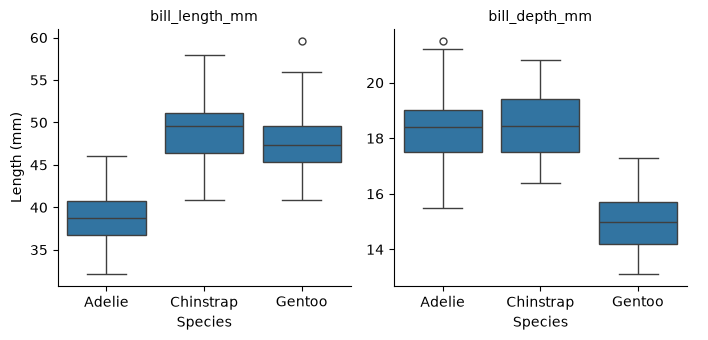

In [49]:
grid = sns.catplot(
    data=length_data,
    x="species",
    y="length_mm",
    col="measurement",
    order=species_order,
    kind="box",
    sharey=False,
    height=3.5,
    aspect=1,
)
grid.set_axis_labels("Species", "Length (mm)")
grid.set_titles("{col_name}")
plt.show()

## IV. Multiple regression for a numeric response

Simple regression uses one predictor. Multiple regression uses several predictors
to summarize the conditional mean of one numeric response. This is often called
multivariable regression; it does not mean that several responses are modeled.

The formula below keeps mass as the response. `+` adds predictor terms, and
`C(species)` treats species as categorical. The model estimates differences
relative to a reference species rather than treating category names as numbers.
A numeric coefficient describes a modeled change holding the other predictors
fixed. That conditional comparison does not establish cause and effect.
Use identical rows when comparing models.



In [50]:
model_data = penguins.dropna(
    subset=["body_mass_g", "flipper_length_mm", "bill_length_mm", "species"]
).copy()
simple_model = smf.ols("body_mass_g ~ flipper_length_mm", data=model_data).fit()
multiple_model = smf.ols(
    "body_mass_g ~ flipper_length_mm + bill_length_mm + C(species)", data=model_data
).fit()
multiple_model.params

Intercept                 -3904.386797
C(species)[T.Chinstrap]    -748.562279
C(species)[T.Gentoo]         90.435311
flipper_length_mm            27.428831
bill_length_mm               61.736447
dtype: float64

In [51]:
comparison = pd.DataFrame(
    {
        "model": ["Simple", "Multiple"],
        "r_squared": [simple_model.rsquared, multiple_model.rsquared],
        "adjusted_r_squared": [simple_model.rsquared_adj, multiple_model.rsquared_adj],
    }
)
comparison

,model,r_squared,adjusted_r_squared
0,Simple,0.758993,0.758284
1,Multiple,0.822244,0.820134


R-squared summarizes in-sample variation explained and cannot decrease when
predictors are added to this ordinary least-squares model on the same rows.
Adjusted R-squared accounts for the number of terms; neither is a test-set score.
Do not choose a model solely because its R-squared is larger. Strongly related
predictors can make individual coefficient estimates unstable.



**Question 5**

Interpret the flipper-length coefficient and one species coefficient using correct units and conditional language. Identify the reference species from the coefficient labels. Explain why a larger in-sample R-squared is insufficient evidence of reliable prediction.

**Answer:** Holding bill length and species fixed, a 1 mm increase in flipper length is associated with about 27.43 g higher fitted body mass. Holding both lengths fixed, Chinstrap penguins have about 748.56 g lower fitted mass than Adelie penguins. Adelie is the reference species because only Chinstrap and Gentoo appear in the species coefficient labels. The larger in-sample R-squared describes fit to these rows; reliable prediction requires evaluation on new or held-out data.


Predictions from a multiple regression depend on all predictors. A single line
on a two-dimensional scatterplot cannot display the whole model. Diagnostic
plots can instead compare fitted values and residuals across species.
`.fittedvalues` and `.resid` retain the model rows; residual is observed minus fitted.
The identity line shows perfect agreement and the zero line shows zero residual.



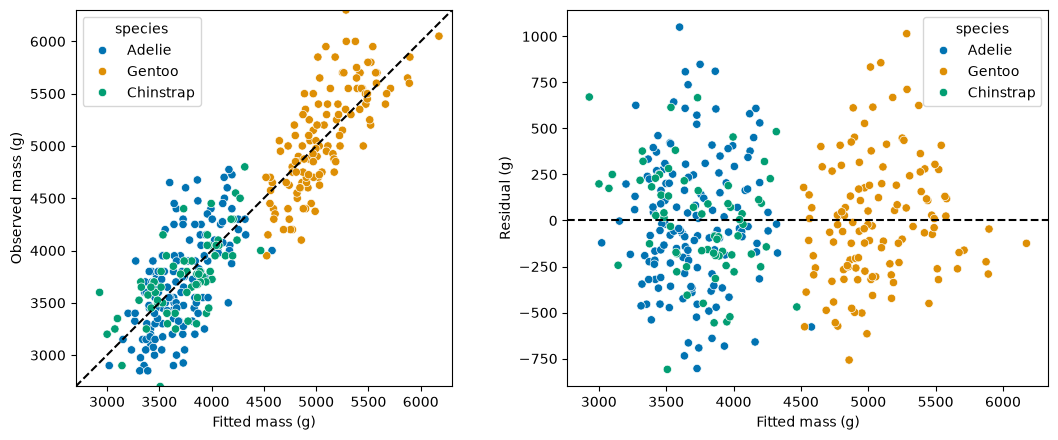

In [52]:
diagnostics = model_data.assign(
    fitted_g=multiple_model.fittedvalues, residual_g=multiple_model.resid
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(
    data=diagnostics,
    x="fitted_g",
    y="body_mass_g",
    hue="species",
    palette="colorblind",
    ax=axes[0],
)
limits = [
    min(diagnostics["fitted_g"].min(), diagnostics["body_mass_g"].min()),
    max(diagnostics["fitted_g"].max(), diagnostics["body_mass_g"].max()),
]
axes[0].plot(limits, limits, color="black", linestyle="--")
axes[0].set(
    xlim=limits, ylim=limits, xlabel="Fitted mass (g)", ylabel="Observed mass (g)"
)
axes[0].set_aspect("equal", adjustable="box")
sns.scatterplot(
    data=diagnostics,
    x="fitted_g",
    y="residual_g",
    hue="species",
    palette="colorblind",
    ax=axes[1],
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Fitted mass (g)", ylabel="Residual (g)")
fig.tight_layout()
plt.show()

**Question 6**

Identify residual structure, changing spread, or unusual observations, using specific visual evidence. Explain one issue these graphs cannot resolve, such as independence of the observations.

**Answer:** The points generally follow the identity line, and residuals fall on both sides of zero. Some errors are large: an Adelie penguin has fitted mass near 3,600 g but observed mass 4,650 g, giving a residual near +1,050 g. A Gentoo penguin also has a residual near +1,015 g. These graphs cannot establish whether observations are independent; that requires information about how the penguins were sampled.


For the following check, `np.linspace(start, stop, num)` makes evenly spaced
values. A prediction DataFrame needs the same predictor column names used in the
formula. `model.predict(new_table)` evaluates the fitted model on those settings.
Only use combinations plausibly supported by the data.



**Question 7**

Make a prediction table for Adelie penguins at several observed-range flipper lengths, holding bill length at the Adelie median. Plot the resulting conditional fitted line and state what is held fixed. This line is not the entire multiple regression surface.

**Answer:** Species is fixed at Adelie and bill length is fixed at the Adelie median of 38.8 mm. Flipper lengths run from the observed Adelie minimum of 172 mm to the maximum of 210 mm. The line shows conditional fitted mass for these settings, not the whole model. Observed ranges alone do not guarantee that every combination is well supported.


,flipper_length_mm,bill_length_mm,species,predicted_g
0,172.000000,38.8,Adelie,3208.746330
1,176.222222,38.8,Adelie,3324.556951
2,180.444444,38.8,Adelie,3440.367572
3,184.666667,38.8,Adelie,3556.178193
4,188.888889,38.8,Adelie,3671.988814
5,193.111111,38.8,Adelie,3787.799434
6,197.333333,38.8,Adelie,3903.610055
7,201.555556,38.8,Adelie,4019.420676
8,205.777778,38.8,Adelie,4135.231297
9,210.000000,38.8,Adelie,4251.041918


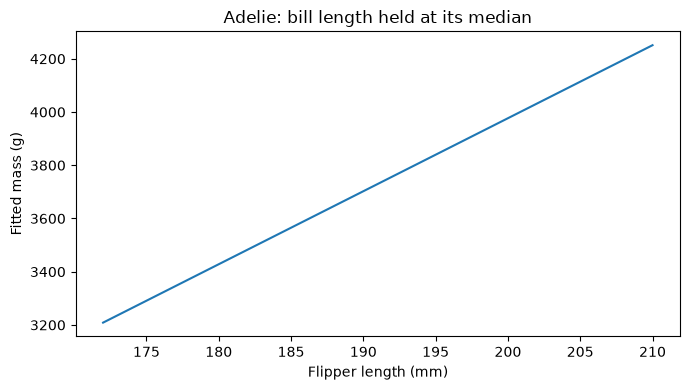

In [53]:
adelie = model_data.loc[model_data["species"].eq("Adelie")]
settings = pd.DataFrame({
    "flipper_length_mm": np.linspace(
        adelie["flipper_length_mm"].min(), adelie["flipper_length_mm"].max(), 10
    ),
    "bill_length_mm": adelie["bill_length_mm"].median(),
    "species": "Adelie",
})
settings["predicted_g"] = multiple_model.predict(settings)
display(settings)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(settings["flipper_length_mm"], settings["predicted_g"])
ax.set(xlabel="Flipper length (mm)", ylabel="Fitted mass (g)",
       title="Adelie: bill length held at its median")
fig.tight_layout()
plt.show()

<div style="height:180px" aria-hidden="true"></div>

---

### Check your work — Question 7

Attempt the question and write your response before reading this section.

The line describes one species at one fixed bill length. Even marginally observed-range values do not guarantee every predictor combination is well supported.



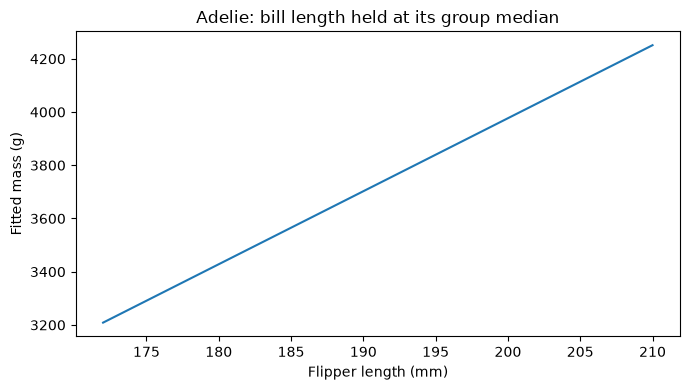

In [54]:
adelie = model_data.loc[model_data["species"].eq("Adelie")]
settings = pd.DataFrame(
    {
        "flipper_length_mm": np.linspace(
            adelie["flipper_length_mm"].min(), adelie["flipper_length_mm"].max(), 40
        ),
        "bill_length_mm": adelie["bill_length_mm"].median(),
        "species": "Adelie",
    }
)
settings["predicted_g"] = multiple_model.predict(settings)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(settings["flipper_length_mm"], settings["predicted_g"])
ax.set(
    xlabel="Flipper length (mm)",
    ylabel="Fitted mass (g)",
    title="Adelie: bill length held at its group median",
)
fig.tight_layout()
plt.show()

## V. Independent investigation

Keep this work separate from the worked examples. It has no supplied solution.



**Question 8**

Investigate a new numeric-response question using Penguins. Use body mass with bill depth and flipper length plus species, or use flipper length with bill length and bill depth plus species. Document complete rows, show grouped and faceted views, fit a multiple regression, inspect observed-versus-fitted and residual plots, and interpret one conditional coefficient. Preserve and revise an overly complex chart. Explain your display choice, supported conclusion, model limitation, and why your in-sample analysis cannot establish causation or unseen-data performance.

**Answer:** My question is: how is body mass related to bill depth and flipper length after accounting for species? The analysis keeps 342 of 344 rows, removing 2 rows missing required measurements. The first chart is too busy because size, color, and shape compete for attention. I preserved it below, then revised it to use color and shape only for species, with facets for within-species comparisons. Holding flipper length and species fixed, 1 mm greater bill depth is associated with about 182.36 g higher fitted mass. The model explains about 83.2% of the mass variation in these rows. Observed masses generally follow the identity line, but the residual plot still has large errors: one Gentoo residual is about +1,100 g, and one Adelie residual is about -900 g. Residuals occur on both sides of zero across the fitted range. The model assumes straight-line effects and the same slopes for all species, which may miss group-specific patterns. The grouped chart shows that Gentoo penguins tend to be heavier despite having shallower bills; the facets make the positive within-species relationships clearer. These are observational data, so unmeasured factors could explain some associations and we cannot claim causation. The model was fitted and checked on the same rows; held-out data are needed to assess prediction accuracy on unseen penguins.


Original rows: 344 Complete rows: 342
Rows removed: 2


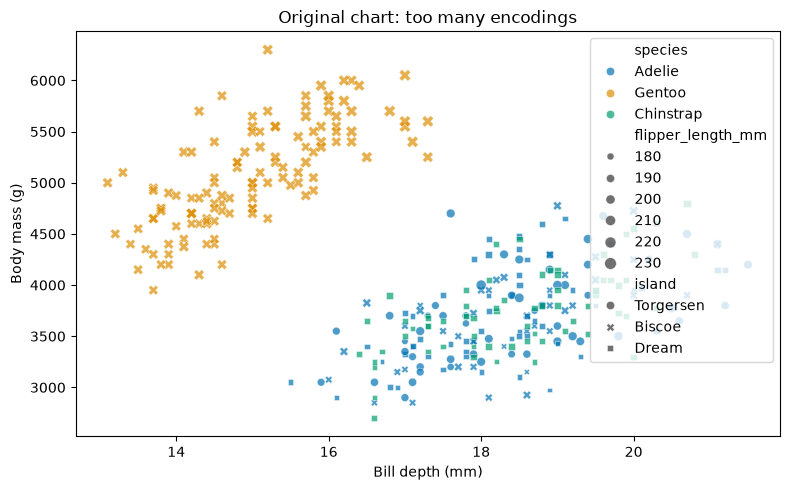

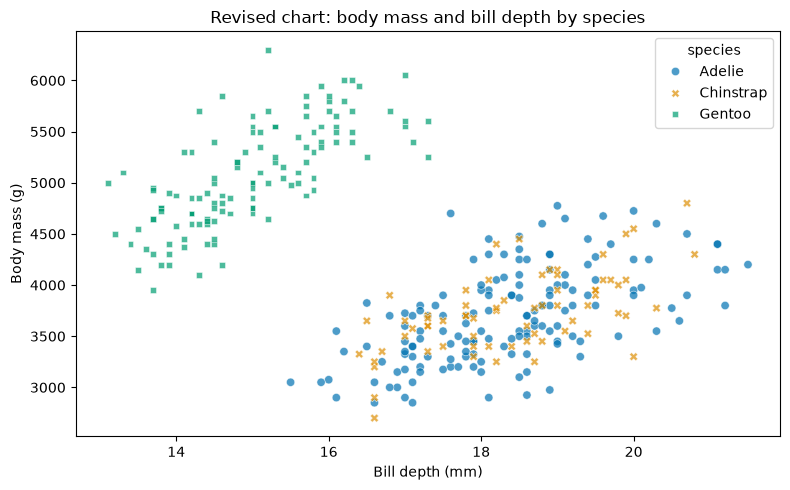

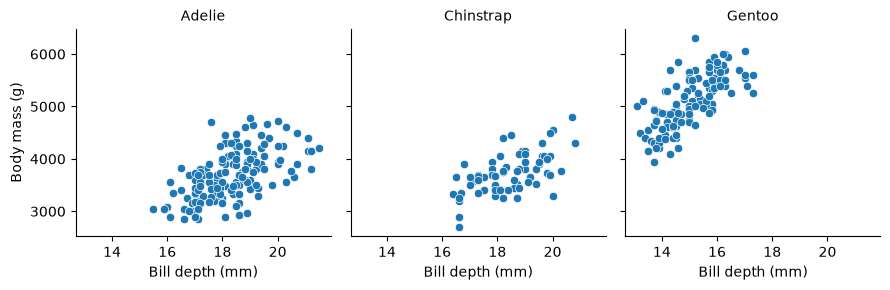

Intercept                 -4526.886816
C(species)[T.Chinstrap]    -131.968044
C(species)[T.Gentoo]       1288.968349
bill_depth_mm               182.363682
flipper_length_mm            25.700164
dtype: float64

R-squared: 0.8318756742433626


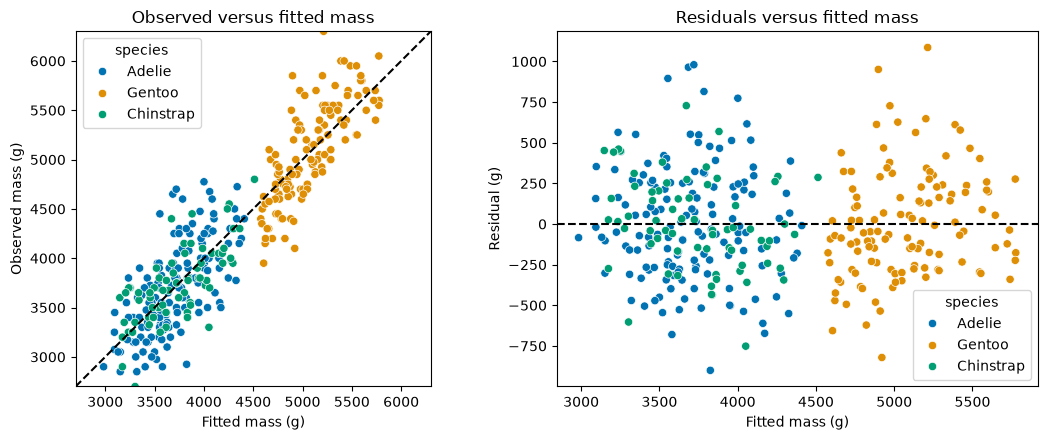

In [55]:
investigation_data = penguins.dropna(
    subset=["body_mass_g", "bill_depth_mm", "flipper_length_mm", "species"]
).copy()
print("Original rows:", len(penguins), "Complete rows:", len(investigation_data))
print("Rows removed:", len(penguins) - len(investigation_data))

# Preserve the overly complex chart before simplifying it.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=investigation_data, x="bill_depth_mm", y="body_mass_g",
    hue="species", style="island", size="flipper_length_mm",
    palette="colorblind", alpha=0.7, ax=ax,
)
ax.set(xlabel="Bill depth (mm)", ylabel="Body mass (g)",
       title="Original chart: too many encodings")
fig.tight_layout()
plt.show()

# Revised grouped chart.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=investigation_data, x="bill_depth_mm", y="body_mass_g",
    hue="species", style="species", hue_order=species_order,
    style_order=species_order, palette="colorblind", alpha=0.7, ax=ax,
)
ax.set(xlabel="Bill depth (mm)", ylabel="Body mass (g)",
       title="Revised chart: body mass and bill depth by species")
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()
fig.tight_layout()
plt.show()

grid = sns.relplot(
    data=investigation_data, x="bill_depth_mm", y="body_mass_g",
    col="species", col_order=species_order, kind="scatter",
    height=3, aspect=1, facet_kws={"sharex": True, "sharey": True},
)
grid.set(xlim=x_limits, ylim=y_limits)
grid.set_axis_labels("Bill depth (mm)", "Body mass (g)")
grid.set_titles("{col_name}")
plt.show()

investigation_model = smf.ols(
    "body_mass_g ~ bill_depth_mm + flipper_length_mm + C(species)",
    data=investigation_data,
).fit()
display(investigation_model.params)
print("R-squared:", investigation_model.rsquared)

investigation_diagnostics = investigation_data.assign(
    fitted_g=investigation_model.fittedvalues,
    residual_g=investigation_model.resid,
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(
    data=investigation_diagnostics, x="fitted_g", y="body_mass_g",
    hue="species", palette="colorblind", ax=axes[0],
)
limits = [
    min(investigation_diagnostics["fitted_g"].min(), investigation_diagnostics["body_mass_g"].min()),
    max(investigation_diagnostics["fitted_g"].max(), investigation_diagnostics["body_mass_g"].max()),
]
axes[0].plot(limits, limits, color="black", linestyle="--")
axes[0].set(xlim=limits, ylim=limits,
            xlabel="Fitted mass (g)", ylabel="Observed mass (g)",
            title="Observed versus fitted mass")
axes[0].set_aspect("equal", adjustable="box")
sns.scatterplot(
    data=investigation_diagnostics, x="fitted_g", y="residual_g",
    hue="species", palette="colorblind", ax=axes[1],
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Fitted mass (g)", ylabel="Residual (g)",
            title="Residuals versus fitted mass")
fig.tight_layout()
plt.show()

## Submission check

- Complete every required question and written **Answer:** area.
- Add your name and date. Optional extension work is not required.
- Restart the kernel and run all cells from top to bottom. Resolve errors.
- Check titles, legends, units, annotations, and written conclusions.
- Export as `Lab7_Multivariate_Visualization.html` and open it to verify the rendered output.
- Submit the completed HTML in Canvas; no separate PNG or `.ipynb` is required.

Late work receives a 10% deduction per day unless an approved arrangement applies.
Use Canvas for the instructor-set deadline and point value.

